# 03 · Evaluate on the test writers

The **test set is used here, once**, after all models are final (`02_train.ipynb`).
The test writers were never seen during training or tuning, so this is our honest estimate of how well the models read *new* people's handwriting.

**Metrics**
* **Accuracy:** share of images guessed right.
* **Top-3 accuracy:** the right letter is among the 3 best guesses (what the app shows).
* **Macro F1:** F1 per letter, averaged, so every letter counts equally.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, torch
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import data as D
from src.model import SimpleCNN
from src.train import predict_probs

X_all, df = D.load_all()
test = (df.split == "test").values
X, y, info = X_all[test], df.label_id.values[test], df[test].reset_index(drop=True)
print(f"test set: {len(X)} images from writers {sorted(info.writer_id.unique())}")

test set: 132 images from writers ['w06', 'w07', 'w13', 'w22']


## 1. Scores of every model

In [2]:
cnn = SimpleCNN(); cnn.load_state_dict(torch.load(ROOT / "models" / "cnn.pt", map_location="cpu")); cnn.eval()
probs = {
    "Logistic regression": joblib.load(ROOT / "models" / "logreg.joblib").predict_proba(X.reshape(len(X), -1)),
    "Random forest":       joblib.load(ROOT / "models" / "forest.joblib").predict_proba(X.reshape(len(X), -1)),
    "Simple CNN":          predict_probs(cnn, X),
}

def top3(p, y):
    return float(np.mean([t in np.argsort(row)[-3:] for row, t in zip(p, y)]))

cv = json.loads((ROOT / "models" / "meta.json").read_text())["cv_accuracy"]
cv_cnn = max(v for k, v in cv.items() if k.startswith("CNN"))
rows = []
for name, p in probs.items():
    pred = p.argmax(1)
    rows.append({"model": name,
                 "CV accuracy (dev)": cv_cnn if name == "Simple CNN" else cv.get(name),
                 "test accuracy": accuracy_score(y, pred), "test top-3": top3(p, y),
                 "test macro F1": f1_score(y, pred, average="macro")})
results = pd.DataFrame(rows).set_index("model").round(3)
results.to_csv(ROOT / "reports" / "test_results.csv")
results

,CV accuracy (dev),test accuracy,test top-3,test macro F1
model,,,,
Logistic regression,0.650,0.523,0.742,0.505
Random forest,0.568,0.462,0.697,0.438
Simple CNN,0.837,0.803,0.947,0.798


## 2. Accuracy per test writer

With only a few test writers, one hard-to-read writer can move the score a lot. This shows how much.

In [3]:
pred = probs["Simple CNN"].argmax(1)
info["correct"] = pred == y
info["predicted"] = [D.ROMAN[k] for k in pred]
print(info.groupby("writer_id").correct.agg(["mean", "size"]).rename(columns={"mean": "CNN accuracy", "size": "images"}).round(3))

           CNN accuracy  images
writer_id                      
w06               0.879      33
w07               0.758      33
w13               0.788      33
w22               0.788      33


## 3. Confusion matrix (CNN)

Row = true letter, column = predicted letter. A perfect model has everything on the diagonal. Off-diagonal cells show which letters get mixed up.

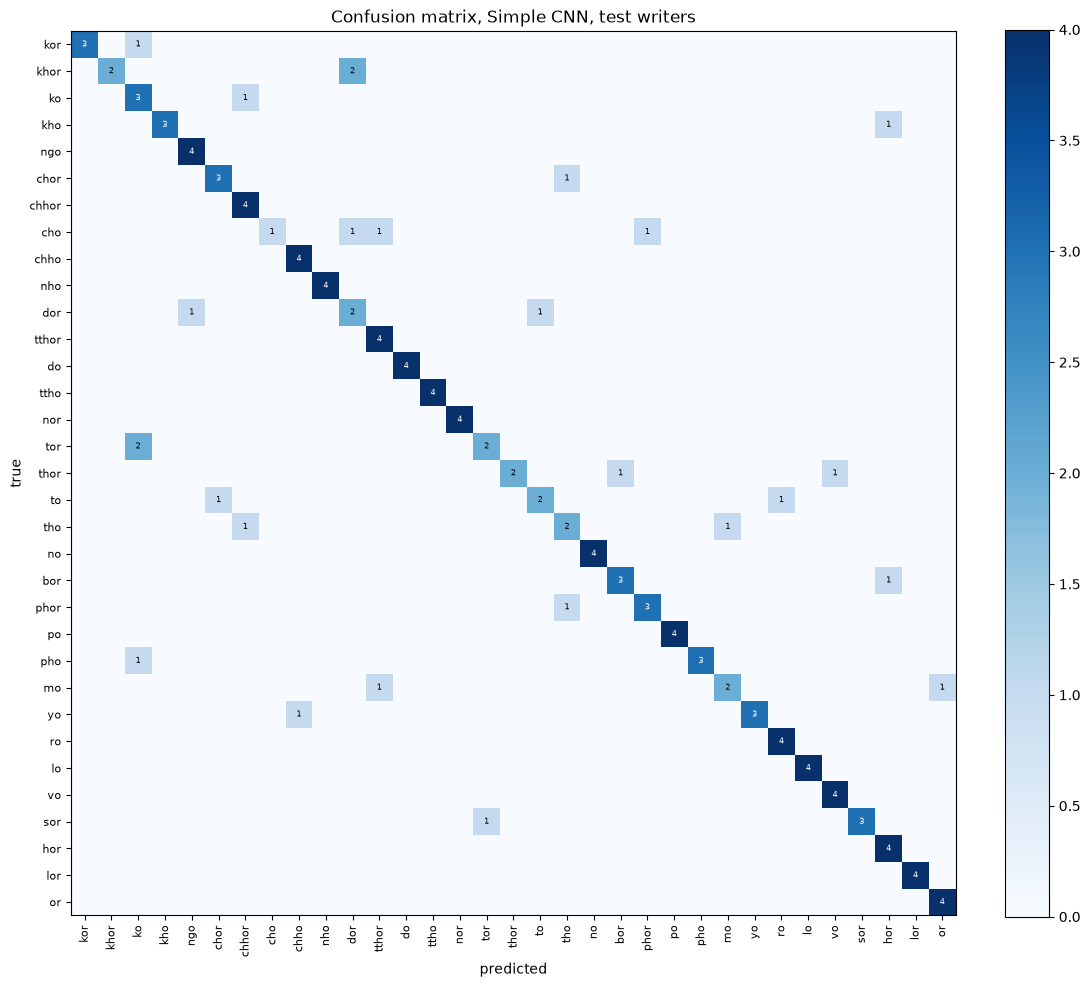

In [4]:
cm = confusion_matrix(y, pred, labels=range(33))
fig, ax = plt.subplots(figsize=(11, 10))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(33)); ax.set_xticklabels(D.ROMAN, rotation=90, fontsize=8)
ax.set_yticks(range(33)); ax.set_yticklabels(D.ROMAN, fontsize=8)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Confusion matrix, Simple CNN, test writers")
for i in range(33):
    for j in range(33):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.savefig(ROOT / "reports" / "confusion_matrix.png", dpi=150); plt.show()

## 4. Most confused pairs

We count mistakes in both directions (A read as B, and B read as A).

In [5]:
pairs = []
for i in range(33):
    for j in range(i + 1, 33):
        n = cm[i, j] + cm[j, i]
        if n:
            pairs.append({"pair": f"{D.LETTERS[i]} {D.ROMAN[i]}  ↔  {D.LETTERS[j]} {D.ROMAN[j]}", "a": i, "b": j, "mistakes": int(n)})
pairs = pd.DataFrame(pairs).sort_values("mistakes", ascending=False).head(5).reset_index(drop=True)
pairs[["pair", "mistakes"]]

,pair,mistakes
0,គ ko ↔ ត tor,2
1,ខ khor ↔ ដ dor,2
2,ក kor ↔ គ ko,1
3,ឈ chho ↔ យ yo,1
4,ប bor ↔ ហ hor,1


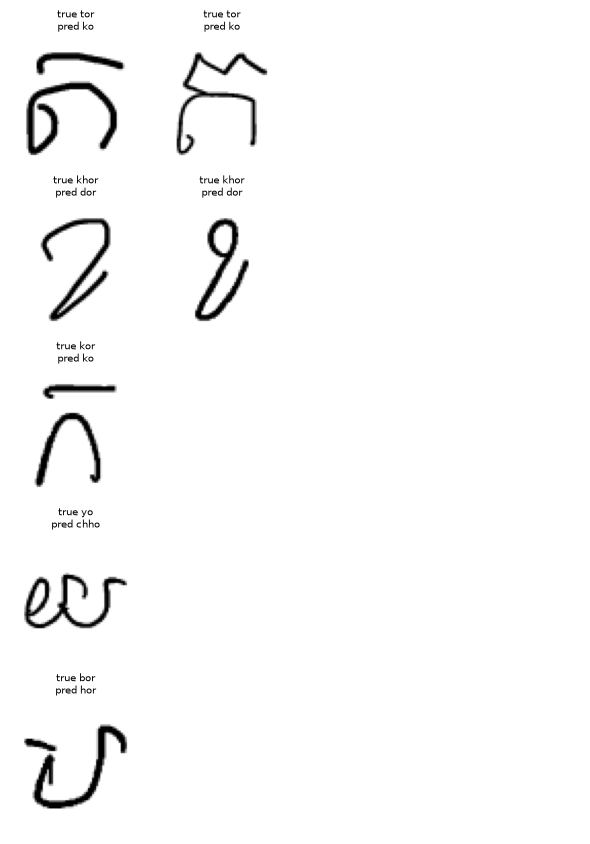

In [6]:
# Real mistakes for the top pairs: what the model saw
wrong = info[~info.correct]
fig, axes = plt.subplots(len(pairs), 4, figsize=(6, 1.7 * len(pairs)), squeeze=False)
for r, p in pairs.iterrows():
    ex = wrong[wrong.label_id.isin([p.a, p.b]) & wrong.predicted.isin([D.ROMAN[p.a], D.ROMAN[p.b]])].head(4)
    for c, a in enumerate(axes[r]):
        a.axis("off")
        if c < len(ex):
            row = ex.iloc[c]
            a.imshow(X[row.name], cmap="gray_r")
            a.set_title(f"true {row.romanization}\npred {row.predicted}", fontsize=7)
plt.tight_layout(); plt.savefig(ROOT / "reports" / "confused_examples.png", dpi=150); plt.show()

## 5. Per-letter scores

In [7]:
report = classification_report(y, pred, labels=range(33), target_names=D.ROMAN, output_dict=True, zero_division=0)
per = pd.DataFrame(report).T.loc[D.ROMAN, ["precision", "recall", "f1-score", "support"]].round(2)
print("Worst 8 letters by F1:")
per.sort_values("f1-score").head(8)

Worst 8 letters by F1:


,precision,recall,f1-score,support
cho,1.00,0.25,0.40,4.0
dor,0.40,0.50,0.44,4.0
tho,0.50,0.50,0.50,4.0
ko,0.43,0.75,0.55,4.0
to,0.67,0.50,0.57,4.0
tor,0.67,0.50,0.57,4.0
mo,0.67,0.50,0.57,4.0
thor,1.00,0.50,0.67,4.0


## 6. What to write in the report

* Copy the table in section 1 into the **Results** section of the README and the report.
* Use `reports/confusion_matrix.png` and `reports/confused_examples.png` for the error analysis. For each top pair, say *why* (the letters differ by one small stroke or loop, an unusual writing style, a bad crop).
* Mention the per-writer spread from section 2: with only 3 test writers the test score has a wide margin of error.
* If accuracy is near 100%, suspect data leakage before celebrating.

## 7. Try the demo app

Run the cell below. It opens the app in your browser (or click the `http://127.0.0.1:7860` link it prints).
Draw a letter and press **Predict**. To stop the app, run `demo.close()` or restart the kernel.

In [8]:
from app.app import demo   # the Gradio app in app/app.py, uses models/cnn.pt

demo.close()               # in case it is already running from an earlier run of this cell
demo.launch(inbrowser=True, prevent_thread_lock=True)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
